# Machine learning · Reducción de dimensión y anomalías

Tres tareas de aprendizaje no supervisado o casi: reducir la dimensión de unos datos (PCA calculado a mano con la SVD y comparado con scikit-learn, reconstrucción, t-SNE), detectar anomalías (z-score, rango intercuartílico, `IsolationForest` y `LocalOutlierFactor`, medidos con precisión y exhaustividad sobre atípicos inyectados) y analizar una serie temporal (descomposición con medias móviles y predicción con retardos validada con `TimeSeriesSplit`). Continúa el ejercicio de PCA de *Clustering y validación*.

## 1. PCA a mano con la SVD

Estandarizar el conjunto de vinos de scikit-learn (`load_wine`, 13 variables) y calcular el PCA con `np.linalg.svd`: las componentes son las filas de $V^T$ y la varianza de cada una es $s_i^2/(n-1)$. Comparar las componentes, la varianza explicada y las coordenadas proyectadas con las de `PCA`, teniendo en cuenta que el signo de cada componente es arbitrario.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

vinos = load_wine()
X = StandardScaler().fit_transform(vinos.data)
n = len(X)

Xc = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
varianzas = s**2 / (n - 1)
ratio = varianzas / varianzas.sum()
proyeccion = Xc @ Vt.T

pca = PCA().fit(X)
signos = np.sign(np.sum(Vt * pca.components_, axis=1))
print("Varianza explicada (a mano):", ratio[:4].round(4))
print("Varianza explicada (PCA):   ", pca.explained_variance_ratio_[:4].round(4))
assert np.allclose(varianzas, pca.explained_variance_)
assert np.allclose(Vt * signos[:, None], pca.components_)
assert np.allclose(proyeccion * signos, pca.transform(X))
assert np.allclose(np.cov(proyeccion, rowvar=False), np.diag(varianzas))

Varianza explicada (a mano): [0.362  0.1921 0.1112 0.0707]
Varianza explicada (PCA):    [0.362  0.1921 0.1112 0.0707]


La última comprobación es la idea del PCA: en las nuevas coordenadas la matriz de covarianzas es diagonal, es decir, las componentes están incorreladas y ordenadas de mayor a menor varianza.

## 2. ¿Cuántas componentes hacen falta?

Con los dígitos escritos a mano (`load_digits`, imágenes de 8×8 = 64 píxeles), dibujar la varianza explicada acumulada y calcular el número mínimo de componentes que conserva el 95 % de la varianza. Comprobar que coincide con el que elige `PCA(n_components=0.95)`.

Componentes para el 95 %: 29 de 64 (0.9548)
  50%: 5 componentes
  80%: 13 componentes
  90%: 21 componentes
  99%: 41 componentes


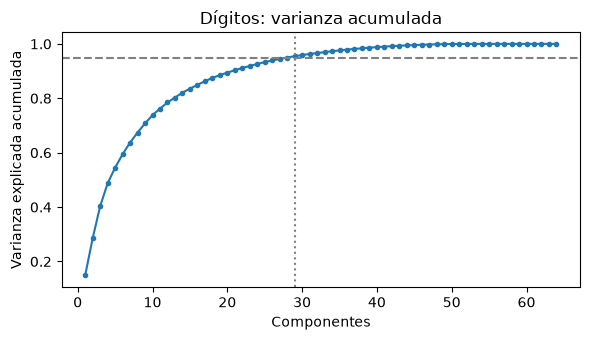

In [2]:
digitos = load_digits()
Xd, yd = digitos.data, digitos.target

pca_d = PCA().fit(Xd)
acumulada = np.cumsum(pca_d.explained_variance_ratio_)
k95 = int(np.searchsorted(acumulada, 0.95) + 1)
print(f"Componentes para el 95 %: {k95} de {Xd.shape[1]} ({acumulada[k95 - 1]:.4f})")
for objetivo in (0.5, 0.8, 0.9, 0.99):
    print(f"  {objetivo:.0%}: {int(np.searchsorted(acumulada, objetivo) + 1)} componentes")
assert PCA(n_components=0.95).fit(Xd).n_components_ == k95

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(acumulada) + 1), acumulada, marker=".")
plt.axhline(0.95, color="gray", ls="--")
plt.axvline(k95, color="gray", ls=":")
plt.xlabel("Componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Dígitos: varianza acumulada")
plt.tight_layout()
plt.show()

## 3. Reconstrucción

Proyectar los dígitos sobre las $k$ primeras componentes y volver al espacio de píxeles con $\hat{X} = Z V_k + \bar{x}$. Calcular el error cuadrático medio para varios $k$, comprobar que coincide con `inverse_transform` y que el error total es la suma de las varianzas de las componentes descartadas. Dibujar un mismo dígito reconstruido con cada $k$.

k =  2: error por imagen   858.94  (varianza descartada   858.94)
k =  5: error por imagen   546.72  (varianza descartada   546.72)
k = 10: error por imagen   314.51  (varianza descartada   314.51)
k = 20: error por imagen   126.99  (varianza descartada   126.99)
k = 29: error por imagen    54.31  (varianza descartada    54.31)
k = 64: error por imagen     0.00  (varianza descartada     0.00)


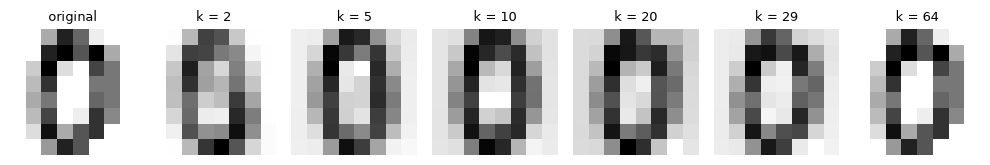

In [3]:
media = Xd.mean(axis=0)
valores_k = [2, 5, 10, 20, k95, 64]
fig, ejes = plt.subplots(1, len(valores_k) + 1, figsize=(10, 1.9))
ejes[0].imshow(Xd[0].reshape(8, 8), cmap="gray_r")
ejes[0].set_title("original", fontsize=9)
for eje, k in zip(ejes[1:], valores_k):
    Vk = pca_d.components_[:k]
    reconstruido = (Xd - media) @ Vk.T @ Vk + media
    assert np.allclose(reconstruido, PCA(k).fit(Xd).inverse_transform(PCA(k).fit(Xd).transform(Xd)))
    ecm = np.mean(np.sum((Xd - reconstruido) ** 2, axis=1))
    descartada = pca_d.explained_variance_[k:].sum() * (len(Xd) - 1) / len(Xd)
    print(f"k = {k:2}: error por imagen {ecm:8.2f}  (varianza descartada {descartada:8.2f})")
    assert np.isclose(ecm, descartada)
    eje.imshow(reconstruido[0].reshape(8, 8), cmap="gray_r")
    eje.set_title(f"k = {k}", fontsize=9)
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

## 4. Los dígitos en dos dimensiones

Proyectar los 1797 dígitos sobre las dos primeras componentes y dibujarlos coloreados por su etiqueta, con el número escrito en el centro de cada grupo. Indicar qué porcentaje de la varianza se conserva y qué pareja de dígitos tiene los centros más próximos.

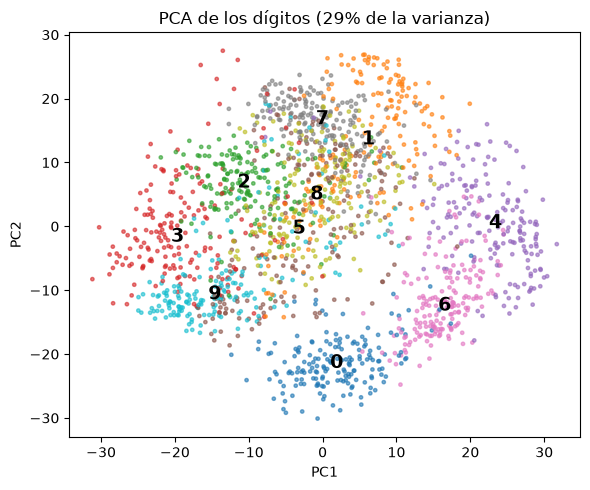

Varianza conservada: 28.5%; pareja de centros más próxima: 5 y 8


In [4]:
Z2 = PCA(2).fit_transform(Xd)
plt.figure(figsize=(6, 5))
plt.scatter(Z2[:, 0], Z2[:, 1], c=yd, cmap="tab10", s=6, alpha=0.6)
for d in range(10):
    cx, cy = np.median(Z2[yd == d], axis=0)
    plt.text(cx, cy, str(d), fontsize=14, weight="bold", ha="center", va="center")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"PCA de los dígitos ({acumulada[1]:.0%} de la varianza)")
plt.tight_layout()
plt.show()

centros = np.array([Z2[yd == d].mean(axis=0) for d in range(10)])
distancias = np.linalg.norm(centros[:, None] - centros[None], axis=2) + np.eye(10) * 1e9
i, j = np.unravel_index(distancias.argmin(), distancias.shape)
print(f"Varianza conservada: {acumulada[1]:.1%}; pareja de centros más próxima: {i} y {j}")

## 5. t-SNE frente a PCA

Calcular un embebido en 2D de los dígitos con `TSNE` (semilla fija) y dibujarlo junto al de PCA. Medir cuantitativamente qué embebido conserva mejor los vecinos: la exactitud de un `KNeighborsClassifier` con validación cruzada sobre las dos coordenadas y la métrica `trustworthiness`, que vale 1 si los vecinos cercanos en 2D también lo eran en 64 dimensiones.

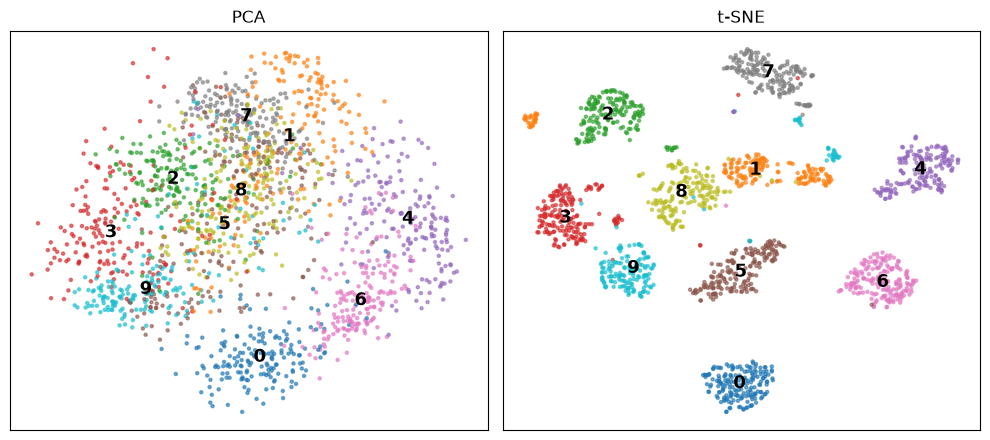

         kNN 2D  trustworthiness
PCA       0.603            0.830
t-SNE     0.976            0.995


In [5]:
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

Zt = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Xd)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5))
for eje, Z, titulo in [(ejes[0], Z2, "PCA"), (ejes[1], Zt, "t-SNE")]:
    eje.scatter(Z[:, 0], Z[:, 1], c=yd, cmap="tab10", s=5, alpha=0.6)
    for d in range(10):
        eje.text(*np.median(Z[yd == d], axis=0), str(d), fontsize=13, weight="bold", ha="center", va="center")
    eje.set_title(titulo)
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

print(f"{'':7}{'kNN 2D':>8}{'trustworthiness':>17}")
metricas = {}
for nombre, Z in [("PCA", Z2), ("t-SNE", Zt)]:
    metricas[nombre] = (cross_val_score(KNeighborsClassifier(5), Z, yd, cv=5).mean(), trustworthiness(Xd, Z, n_neighbors=5))
    print(f"{nombre:7}{metricas[nombre][0]:8.3f}{metricas[nombre][1]:17.3f}")
assert metricas["t-SNE"][0] > metricas["PCA"][0] and metricas["t-SNE"][1] > metricas["PCA"][1]

t-SNE separa mucho mejor los grupos porque solo intenta conservar los vecinos cercanos, pero no es lineal, no tiene `transform` para datos nuevos y las distancias entre grupos y sus tamaños no significan nada. PCA sirve para comprimir y reconstruir; t-SNE, solo para mirar.

## 6. Datos con atípicos inyectados

Generar 500 medidas normales de dos sensores correlacionados (temperatura y humedad de un invernadero) y añadir atípicos de dos clases: hasta 15 muy alejados en alguna variable (se descartan los sorteados que caen dentro del rango normal) y 10 con valores normales en cada variable por separado pero que rompen la correlación. Guardar la etiqueta real (1 = atípico) y dibujarlos.

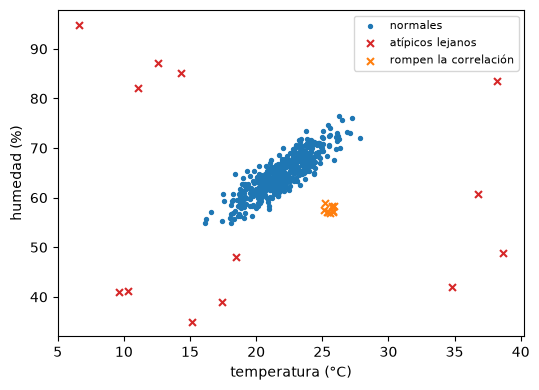

523 medidas, 23 atípicas (4.4%)


In [6]:
rng = np.random.default_rng(11)
normales = rng.multivariate_normal([22, 65], [[4, 7], [7, 16]], size=500)
lejanos = np.column_stack([rng.uniform(5, 40, 15), rng.uniform(20, 100, 15)])
lejanos = lejanos[np.abs((lejanos - [22, 65]) / [2, 4]).max(axis=1) > 3.5]
contrarios = np.column_stack([rng.uniform(25, 26, 10), rng.uniform(57, 59, 10)])
datos = np.vstack([normales, lejanos, contrarios])
real = np.r_[np.zeros(len(normales)), np.ones(len(lejanos) + len(contrarios))].astype(int)

plt.figure(figsize=(5.5, 4))
plt.scatter(*normales.T, s=8, c="tab:blue", label="normales")
plt.scatter(*lejanos.T, s=25, c="tab:red", marker="x", label="atípicos lejanos")
plt.scatter(*contrarios.T, s=25, c="tab:orange", marker="x", label="rompen la correlación")
plt.xlabel("temperatura (°C)")
plt.ylabel("humedad (%)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"{len(datos)} medidas, {real.sum()} atípicas ({real.mean():.1%})")
assert len(lejanos) >= 10

## 7. z-score y rango intercuartílico

Marcar como atípica una medida si en alguna variable su z-score supera 3 en valor absoluto, y con otra regla si cae fuera de $[Q_1 - 1{,}5\,\text{IQR},\ Q_3 + 1{,}5\,\text{IQR}]$. Calcular la precisión y la exhaustividad de cada regla, separando la exhaustividad por clase de atípico: las reglas que miran cada variable por separado no pueden ver los que rompen la correlación.

In [7]:
from sklearn.metrics import f1_score, precision_score, recall_score

z = np.abs((datos - datos.mean(axis=0)) / datos.std(axis=0))
marca_z = (z > 3).any(axis=1).astype(int)

q1, q3 = np.percentile(datos, [25, 75], axis=0)
iqr = q3 - q1
marca_iqr = ((datos < q1 - 1.5 * iqr) | (datos > q3 + 1.5 * iqr)).any(axis=1).astype(int)

clase = np.r_[np.zeros(len(normales)), np.ones(len(lejanos)), 2 * np.ones(len(contrarios))]


def informe(nombre, marca):
    p, r = precision_score(real, marca), recall_score(real, marca)
    r_lej, r_con = marca[clase == 1].mean(), marca[clase == 2].mean()
    print(f"{nombre:18}{p:10.2f}{r:9.2f}{r_lej:9.2f}{r_con:12.2f}")
    return p, r, r_con


print(f"{'':18}{'precisión':>10}{'exhaust.':>9}{'lejanos':>9}{'contrarios':>12}")
resultados = {"z-score": informe("z-score", marca_z), "IQR": informe("IQR", marca_iqr)}
assert resultados["z-score"][2] == 0 and resultados["IQR"][2] == 0

                   precisión exhaust.  lejanos  contrarios
z-score                 1.00     0.57     1.00        0.00
IQR                     0.72     0.57     1.00        0.00


## 8. `IsolationForest`

Entrenar un `IsolationForest` con `contamination` igual a la proporción real de atípicos. La idea: un punto aislado se separa del resto con pocos cortes aleatorios, así que la profundidad media a la que queda solo en los árboles es una puntuación de anomalía. Calcular la precisión y la exhaustividad y comprobar que la predicción (−1 = atípico) equivale a umbralizar `decision_function` en 0.

In [8]:
from sklearn.ensemble import IsolationForest

bosque = IsolationForest(n_estimators=300, contamination=real.mean(), random_state=0).fit(datos)
marca_bosque = (bosque.predict(datos) == -1).astype(int)
assert np.array_equal(marca_bosque, (bosque.decision_function(datos) < 0).astype(int))
print(f"{'':18}{'precisión':>10}{'exhaust.':>9}{'lejanos':>9}{'contrarios':>12}")
resultados["IsolationForest"] = informe("IsolationForest", marca_bosque)

                   precisión exhaust.  lejanos  contrarios
IsolationForest         0.57     0.57     1.00        0.00


Los cortes de `IsolationForest` son paralelos a los ejes, así que un punto que solo es raro por la combinación de las dos variables cuesta casi lo mismo de aislar que uno normal: aquí detecta los lejanos, pero no los que rompen la correlación, y con `contamination` fijada rellena el cupo con falsas alarmas.

## 9. `LocalOutlierFactor`

`LocalOutlierFactor` compara la densidad de cada punto con la de sus vecinos, así que detecta puntos raros *para su zona*. Aplicarlo a los datos del invernadero y, aparte, a un ejemplo con dos grupos de densidad muy distinta y un punto situado entre ellos, pegado al grupo denso: dentro del rango global de las variables, pero mucho más aislado que cualquier punto de su vecindad. Comprobar que LOF lo marca y el z-score no.

In [9]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, contamination=real.mean())
marca_lof = (lof.fit_predict(datos) == -1).astype(int)
print(f"{'':18}{'precisión':>10}{'exhaust.':>9}{'lejanos':>9}{'contrarios':>12}")
resultados["LOF"] = informe("LOF", marca_lof)

rng2 = np.random.default_rng(5)
denso = rng2.normal([0, 0], 0.3, size=(200, 2))
disperso = rng2.normal([8, 8], 2.5, size=(200, 2))
sospechoso = np.array([[1.8, 1.8]])
mezcla = np.vstack([denso, disperso, sospechoso])
puntuacion = -LocalOutlierFactor(n_neighbors=20).fit(mezcla).negative_outlier_factor_
z_mezcla = np.abs((mezcla - mezcla.mean(axis=0)) / mezcla.std(axis=0)).max(axis=1)
print(f"\nPunto sospechoso: LOF = {puntuacion[-1]:.2f} (puesto {int((puntuacion > puntuacion[-1]).sum()) + 1} de {len(mezcla)}), "
      f"z máximo = {z_mezcla[-1]:.2f}")
assert puntuacion[-1] == puntuacion.max() and z_mezcla[-1] < 3

                   precisión exhaust.  lejanos  contrarios
LOF                     1.00     1.00     1.00        1.00

Punto sospechoso: LOF = 6.92 (puesto 1 de 401), z máximo = 0.51


## 10. Comparar los detectores

Reunir en una tabla la precisión, la exhaustividad y el F1 de los cuatro detectores sobre los datos del invernadero, y dibujar qué puntos marca cada uno. Comprobar que solo LOF, que mira la densidad local, encuentra los atípicos que rompen la correlación.

                   precisión exhaust.    F1
z-score                 1.00     0.57  0.72
IQR                     0.72     0.57  0.63
IsolationForest         0.57     0.57  0.57
LOF                     1.00     1.00  1.00


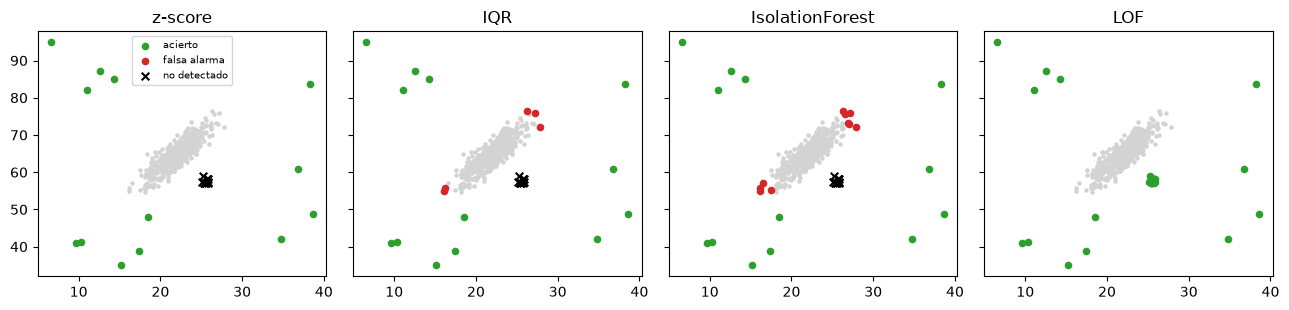

In [10]:
marcas = {"z-score": marca_z, "IQR": marca_iqr, "IsolationForest": marca_bosque, "LOF": marca_lof}
print(f"{'':18}{'precisión':>10}{'exhaust.':>9}{'F1':>6}")
for nombre, marca in marcas.items():
    print(f"{nombre:18}{precision_score(real, marca):10.2f}{recall_score(real, marca):9.2f}{f1_score(real, marca):6.2f}")

fig, ejes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True, sharey=True)
for eje, (nombre, marca) in zip(ejes, marcas.items()):
    eje.scatter(*datos[marca == 0].T, s=5, c="lightgray")
    eje.scatter(*datos[(marca == 1) & (real == 1)].T, s=20, c="tab:green", label="acierto")
    eje.scatter(*datos[(marca == 1) & (real == 0)].T, s=20, c="tab:red", label="falsa alarma")
    eje.scatter(*datos[(marca == 0) & (real == 1)].T, s=30, c="black", marker="x", label="no detectado")
    eje.set_title(nombre)
ejes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
assert resultados["LOF"][2] > max(resultados["IsolationForest"][2], resultados["z-score"][2])

## 11. Serie temporal: tendencia y estacionalidad

Generar 12 años de llegadas mensuales de turistas a una isla (en miles) como suma de una tendencia creciente, una estacionalidad con máximo en invierno y ruido. Descomponerla con medias móviles: la tendencia es la media móvil centrada de orden $2 \times 12$, la estacionalidad es la media por mes de la serie sin tendencia (ajustada para sumar 0) y el residuo es lo que queda. Comparar cada componente estimada con la real y dibujar las cuatro.

Meses con tendencia estimada: 132 de 144 (la media centrada pierde 6 por cada extremo)
Error medio de la tendencia: 2.63 miles
Error medio de la estacionalidad: 2.49 miles
Índices estacionales: {1: 75.0, 2: 61.2, 3: 23.0, 4: -16.8, 5: -41.0, 6: -45.4, 7: -50.9, 8: -41.9, 9: -35.7, 10: -10.7, 11: 26.6, 12: 56.7}


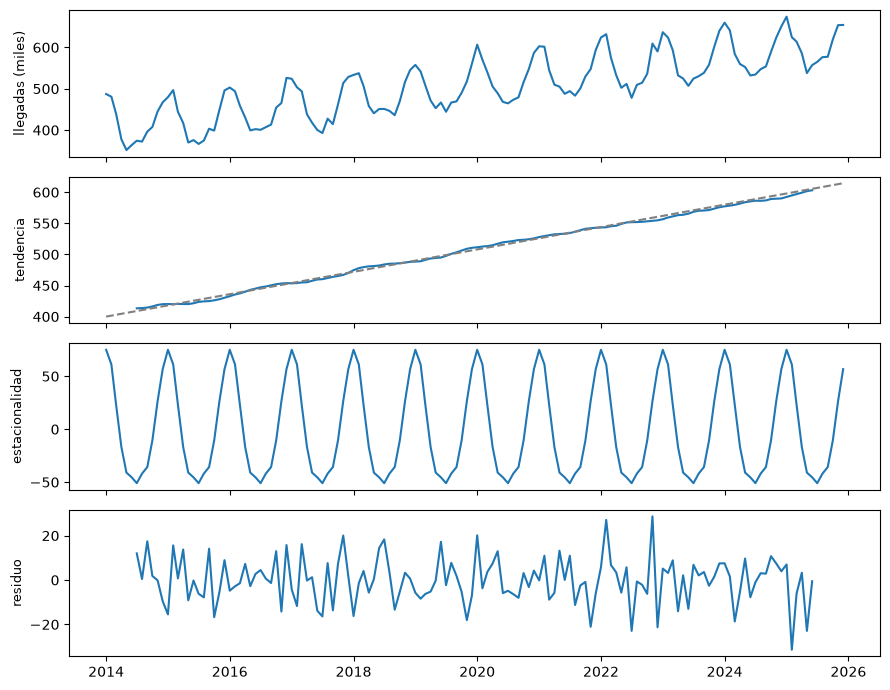

In [11]:
import pandas as pd

rng3 = np.random.default_rng(2024)
fechas = pd.date_range("2014-01", periods=144, freq="MS")
t = np.arange(144)
tendencia_real = 400 + 1.5 * t
estacional_real = 60 * np.cos(2 * np.pi * (fechas.month.to_numpy() - 1) / 12) + 15 * np.cos(4 * np.pi * (fechas.month.to_numpy() - 1) / 12)
llegadas = pd.Series(tendencia_real + estacional_real + rng3.normal(0, 12, 144), index=fechas)

tendencia = llegadas.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
sin_tendencia = llegadas - tendencia
indices = sin_tendencia.groupby(sin_tendencia.index.month).mean()
indices -= indices.mean()
estacional = pd.Series(indices.loc[llegadas.index.month].to_numpy(), index=fechas)
residuo = llegadas - tendencia - estacional

validos = tendencia.notna()
print(f"Meses con tendencia estimada: {validos.sum()} de 144 (la media centrada pierde 6 por cada extremo)")
print(f"Error medio de la tendencia: {np.abs(tendencia[validos] - tendencia_real[validos]).mean():.2f} miles")
print(f"Error medio de la estacionalidad: {np.abs(estacional - estacional_real).mean():.2f} miles")
print("Índices estacionales:", indices.round(1).to_dict())
assert validos.sum() == 132 and np.isclose(indices.sum(), 0)
assert np.abs(estacional - estacional_real).mean() < 8

fig, ejes = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for eje, serie, titulo in zip(ejes, [llegadas, tendencia, estacional, residuo],
                              ["llegadas (miles)", "tendencia", "estacionalidad", "residuo"]):
    eje.plot(serie)
    eje.set_ylabel(titulo, fontsize=9)
ejes[1].plot(fechas, tendencia_real, ls="--", c="gray")
plt.tight_layout()
plt.show()

## 12. `TimeSeriesSplit`

En una serie temporal no se puede barajar: el modelo no debe ver el futuro. Mostrar las particiones de `TimeSeriesSplit(n_splits=5, test_size=12)` sobre los 144 meses (cada una predice un año entero) y comprobar que en todas el entrenamiento termina justo antes de que empiece la prueba y que la ventana de entrenamiento va creciendo.

In [12]:
from sklearn.model_selection import TimeSeriesSplit

particion = TimeSeriesSplit(n_splits=5, test_size=12)
anterior = 0
for i, (ent, pru) in enumerate(particion.split(llegadas), 1):
    print(f"Partición {i}: entrena {fechas[ent[0]]:%Y-%m}..{fechas[ent[-1]]:%Y-%m} ({len(ent):3} meses), "
          f"prueba {fechas[pru[0]]:%Y-%m}..{fechas[pru[-1]]:%Y-%m}")
    assert ent[-1] + 1 == pru[0] and len(pru) == 12 and len(ent) > anterior
    anterior = len(ent)

Partición 1: entrena 2014-01..2020-12 ( 84 meses), prueba 2021-01..2021-12
Partición 2: entrena 2014-01..2021-12 ( 96 meses), prueba 2022-01..2022-12
Partición 3: entrena 2014-01..2022-12 (108 meses), prueba 2023-01..2023-12
Partición 4: entrena 2014-01..2023-12 (120 meses), prueba 2024-01..2024-12
Partición 5: entrena 2014-01..2024-12 (132 meses), prueba 2025-01..2025-12


## 13. Predicción con retardos frente a la línea base ingenua

Construir variables de retardo (el valor de hace 1, 2, 3 y 12 meses) y el índice del mes, entrenar una `LinearRegression` y validarla con las particiones del ejercicio anterior. Compararla con dos líneas base: la ingenua (el mes que viene será como este) y la ingenua estacional (será como el mismo mes del año pasado). Mostrar el error absoluto medio de cada método por partición y dibujar las predicciones del último año.

partición   ingenua  estacional  regresión
1              21.6        13.5        9.9
2              30.1        21.6       16.0
3              25.8        19.8       11.8
4              22.2        19.7        8.9
5              23.1        22.8       13.6
media          24.5        19.5       12.0


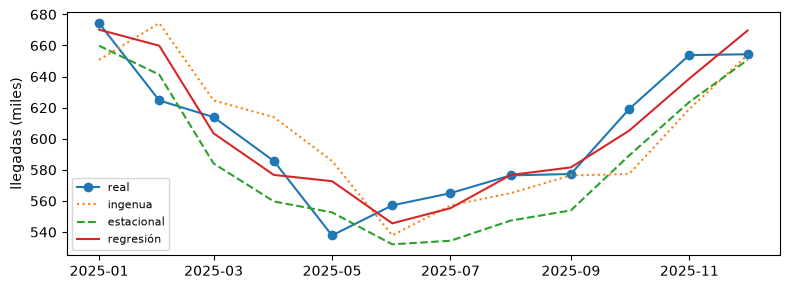

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

tabla = pd.DataFrame({"y": llegadas, "t": t})
for retardo in (1, 2, 3, 12):
    tabla[f"retardo_{retardo}"] = llegadas.shift(retardo)
tabla = tabla.dropna()
variables = [c for c in tabla.columns if c != "y"]

errores = {"ingenua": [], "estacional": [], "regresión": []}
print(f"{'partición':10}{'ingenua':>9}{'estacional':>12}{'regresión':>11}")
for i, (ent, pru) in enumerate(TimeSeriesSplit(n_splits=5, test_size=12).split(tabla), 1):
    entrenamiento, prueba = tabla.iloc[ent], tabla.iloc[pru]
    modelo = LinearRegression().fit(entrenamiento[variables], entrenamiento["y"])
    pred = modelo.predict(prueba[variables])
    errores["ingenua"].append(mean_absolute_error(prueba["y"], prueba["retardo_1"]))
    errores["estacional"].append(mean_absolute_error(prueba["y"], prueba["retardo_12"]))
    errores["regresión"].append(mean_absolute_error(prueba["y"], pred))
    print(f"{i:<10}{errores['ingenua'][-1]:9.1f}{errores['estacional'][-1]:12.1f}{errores['regresión'][-1]:11.1f}")
medias = {k: np.mean(v) for k, v in errores.items()}
print(f"{'media':10}{medias['ingenua']:9.1f}{medias['estacional']:12.1f}{medias['regresión']:11.1f}")
assert medias["regresión"] < medias["estacional"] < medias["ingenua"]

plt.figure(figsize=(8, 3))
plt.plot(prueba.index, prueba["y"], marker="o", label="real")
plt.plot(prueba.index, prueba["retardo_1"], ls=":", label="ingenua")
plt.plot(prueba.index, prueba["retardo_12"], ls="--", label="estacional")
plt.plot(prueba.index, pred, label="regresión")
plt.ylabel("llegadas (miles)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Estas predicciones son a un mes vista: usan el valor real del mes anterior. Para predecir un año entero de golpe habría que alimentar el modelo con sus propias predicciones (predicción recursiva) y el error crecería con el horizonte.